In [1]:
import mdtraj as md
import numpy as np
import matplotlib.pyplot as plt
import os
import pickle


pickle_dir = "./pickle-cache/base-bulge"
if not os.path.exists(pickle_dir):
    os.mkdir(pickle_dir)

gleap_target = md.load("../20250801_FUS-RRM/2_md-preparation-2/gleap.target.gro")
atom_indices_protein = gleap_target.topology.select("resid 23 to 126")
atom_indices_rna     = gleap_target.topology.select("resid  0 to  22")


xtcs = []
interactions = np.zeros((5, 18000, 4))
for trial in range(5):
    xtc = md.load(f"../20250801_FUS-RRM/6_cmd-{trial+1}/cmd.skip10.whole.target.pbc.xtc", top=gleap_target)[2001:]
    xtcs.append(xtc)
    print(trial, xtc.n_frames)
    # xyzs_rrm_ca = xtc.atom_slice(xtc.topology.select("(resid 34 to 38 or resid 70 to 72 or resid 84 to 88 or resid 110 to 116) and (name CA)")).xyz
    xyzs_rrm_ca = xtc.atom_slice(xtc.topology.select("(resid 33 to 116) and (name CA)")).xyz
    for residue_index_rna in range(11, 15):
        coms_rna_base     = xtc.atom_slice(xtc.topology.select(f"(resid {residue_index_rna}) and (name N1 or name C2 or name O2 or name N3 or name H3 or name C4 or name O4 or name C5 or name H5 or name C6 or name H6 or name N4 or name H41 or name H42 or name H2 or name N6 or name H61 or name H62 or name N7 or name C8 or name H8 or name N9)")).xyz.mean(axis=1)
        coms_rna_backbone = xtc.atom_slice(xtc.topology.select(f"(resid {residue_index_rna}) and (name \"O3'\" or name \"C3'\" or name \"H3'\" or name \"C4'\" or name \"H4'\" or name \"C5'\")")).xyz.mean(axis=1)

        distances_rrm_rna_base     = np.linalg.norm(xyzs_rrm_ca-coms_rna_base    [:, np.newaxis, :], axis=2).min(axis=1)
        distances_rrm_rna_backbone = np.linalg.norm(xyzs_rrm_ca-coms_rna_backbone[:, np.newaxis, :], axis=2).min(axis=1)

        interactions[trial, :, residue_index_rna-11] = (distances_rrm_rna_base > distances_rrm_rna_backbone).astype(int)

pickle.dump(interactions, open(f"{pickle_dir}/interactions.pickle", "wb"))

0 18000
1 18000
2 18000
3 18000
4 18000


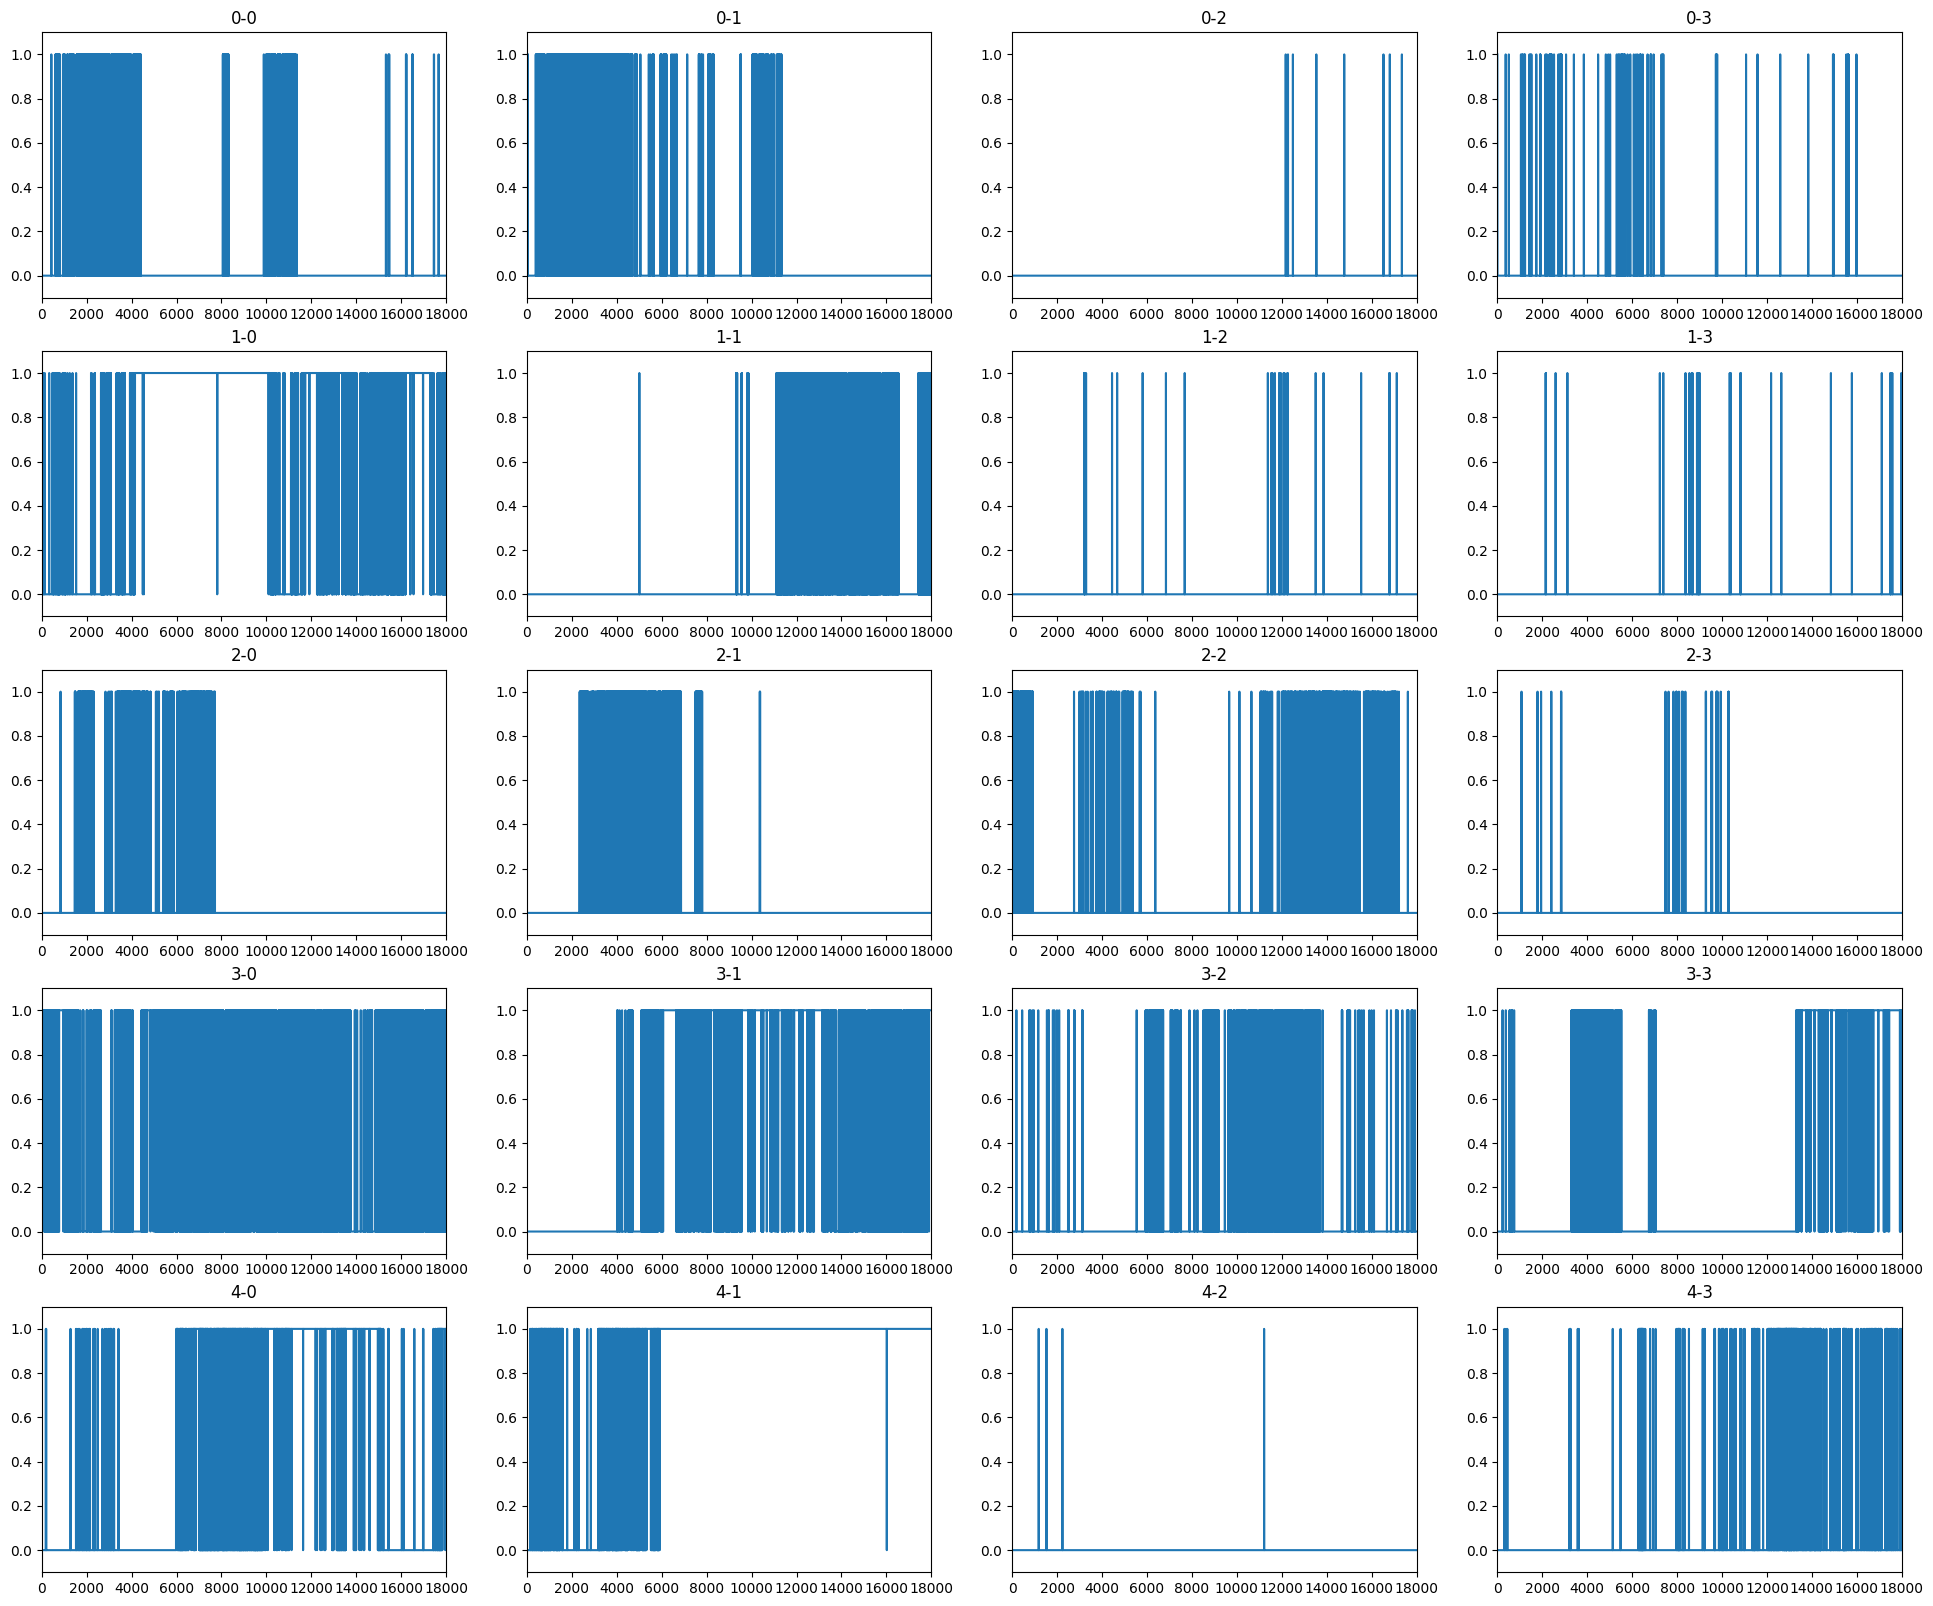

In [2]:
fig, ax = plt.subplots(len(interactions), 4)
fig.set_size_inches(24, 4*len(interactions))

for trial in range(len(interactions)):
    for residue_index_rna in range(4):
        ax[trial, residue_index_rna].plot(interactions[trial, : , residue_index_rna])
        ax[trial, residue_index_rna].set_title(f"{trial}-{residue_index_rna}")
        ax[trial, residue_index_rna].set_xlim(0, 18000)

        ax[trial, residue_index_rna].set_ylim(-0.1, 1.1)

In [3]:
for residue_index_rna in range(4):
    xtcs_state0 = []
    xtcs_state1 = []
    
    for trial in range(len(xtcs)):
        xtcs_state0.append(xtcs[trial][interactions[trial, :, residue_index_rna]==0][::10])
        xtcs_state1.append(xtcs[trial][interactions[trial, :, residue_index_rna]==1][::10])

    md.join(xtcs_state0).superpose(gleap_target).save_xtc(f"base-bulge/{residue_index_rna}-0.xtc")
    md.join(xtcs_state1).superpose(gleap_target).save_xtc(f"base-bulge/{residue_index_rna}-1.xtc")

In [4]:
from sklearn.metrics import classification_report


metastabled_trajs_concat = pickle.load(open(f"./pickle-cache/pca_tetranucl/metastabled_trajs_concat_2.pickle", "rb"))
interactions_concat = np.concatenate(interactions)

for residue_index_rna in range(4):
    print(classification_report(metastabled_trajs_concat, interactions_concat[:,residue_index_rna]))

              precision    recall  f1-score   support

         0.0       0.38      0.96      0.55     24995
         1.0       0.97      0.40      0.57     65005

    accuracy                           0.56     90000
   macro avg       0.67      0.68      0.56     90000
weighted avg       0.80      0.56      0.56     90000

              precision    recall  f1-score   support

         0.0       0.39      0.96      0.55     24995
         1.0       0.96      0.42      0.59     65005

    accuracy                           0.57     90000
   macro avg       0.68      0.69      0.57     90000
weighted avg       0.80      0.57      0.58     90000

              precision    recall  f1-score   support

         0.0       0.28      0.99      0.43     24995
         1.0       0.76      0.02      0.03     65005

    accuracy                           0.29     90000
   macro avg       0.52      0.50      0.23     90000
weighted avg       0.63      0.29      0.15     90000

              preci

In [5]:
from sklearn.metrics import confusion_matrix

for residue_index_rna in range(4):
    print(confusion_matrix(metastabled_trajs_concat, interactions_concat[:,residue_index_rna]))

[[24068   927]
 [38950 26055]]
[[23883  1112]
 [37515 27490]]
[[24635   360]
 [63865  1140]]
[[24890   105]
 [58841  6164]]
